In [1]:
from sklearn.datasets import load_diabetes

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [2]:
X,y = load_diabetes(return_X_y=True)

In [3]:
print(X.shape)
print(y.shape)


(442, 10)
(442,)


In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [5]:
reg = LinearRegression()
reg.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [6]:
print(reg.coef_)
print(reg.intercept_)

[  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238]
151.88331005254167


In [7]:
y_pred = reg.predict(X_test)
r2_score(y_test,y_pred)


0.4399338661568969

In [8]:
X_train.shape


(353, 10)

In [34]:
X_train[:,1].shape


(353,)

In [35]:
'''class GDRegressor:
    def __init__(self,learning_rate=0.01,epochs=100):
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs 
    def fit(self,X_train,y_train):
        #initialize ur coeffs 
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])

        for i in range(self.epochs):
            #update all the coeffs and the intercept 
            y_hat = np.dot(X_train,self.coef_) + self.intercept_ 
            #print("Shape of y_hat",y_hat.shape)
            intercept_der = -2 * np.mean(y_train - y_hat   )
            self.intercept_ = self.intercept_ - (self.lr * intercept_der)
            for j in range(X.shape[1]):
                coef_der = -2 * np.mean((y_train - y_hat) * X_train[:,j]) 
            self.coef_ = self.coef_ - (self.lr * coef_der)

        print(self.intercept_,self.coef_)

    def predict(self,X_test):
        pass'''

'class GDRegressor:\n    def __init__(self,learning_rate=0.01,epochs=100):\n        self.coef_ = None\n        self.intercept_ = None\n        self.lr = learning_rate\n        self.epochs = epochs \n    def fit(self,X_train,y_train):\n        #initialize ur coeffs \n        self.intercept_ = 0\n        self.coef_ = np.ones(X_train.shape[1])\n\n        for i in range(self.epochs):\n            #update all the coeffs and the intercept \n            y_hat = np.dot(X_train,self.coef_) + self.intercept_ \n            #print("Shape of y_hat",y_hat.shape)\n            intercept_der = -2 * np.mean(y_train - y_hat   )\n            self.intercept_ = self.intercept_ - (self.lr * intercept_der)\n            for j in range(X.shape[1]):\n                coef_der = -2 * np.mean((y_train - y_hat) * X_train[:,j]) \n            self.coef_ = self.coef_ - (self.lr * coef_der)\n\n        print(self.intercept_,self.coef_)\n\n    def predict(self,X_test):\n        pass'

In [36]:
class GDRegressor:
    def __init__(self,learning_rate=0.01,epochs=100):
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs 
    def fit(self,X_train,y_train):
        #initialize ur coeffs 
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])

        for i in range(self.epochs):
            #update all the coeffs and the intercept 
            y_hat = np.dot(X_train,self.coef_) + self.intercept_ 
            #print("Shape of y_hat",y_hat.shape)
            intercept_der = -2 * np.mean(y_train - y_hat   )
            self.intercept_ = self.intercept_ - (self.lr * intercept_der)

            coef_der = -2 * np.dot((y_train - y_hat),X_train)/ X_train.shape[0]
            self.coef_ = self.coef_ - (self.lr * coef_der)

        print(self.intercept_,self.coef_)

    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_ 

In [37]:
gdr=GDRegressor(epochs=100, learning_rate = 0.01)

In [38]:
gdr.fit(X_train,y_train)

130.52896930987225 [ 2.63772241  1.19060622  5.06046267  4.31375004  2.44715577  1.99246132
 -1.48838841  3.60218122  5.24193975  3.51394813]


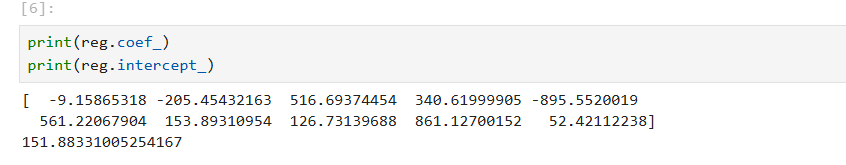

In [39]:
# we can see that our actual values a bigger and intercept was also larger 

In [40]:
y_pred = gdr.predict(X_test)

In [41]:
r2_score(y_test,y_pred)

-0.12800129775948377

In [43]:
gdr=GDRegressor(epochs=100, learning_rate = 0.1)
gdr.fit(X_train,y_train)
y_pred = gdr.predict(X_test)
r2_score(y_test,y_pred)

150.7531599983413 [ 15.99508569   3.60384187  41.67775463  32.56961741  14.78846879
  11.44465168 -24.68352239  27.66505407  41.21068208  25.19906977]


0.10373361949035997

In [44]:
gdr=GDRegressor(epochs=1000, learning_rate = 0.1)
gdr.fit(X_train,y_train)

151.94042847773682 [  62.27835432  -24.14017912  262.40285385  192.20751489   39.48809013
   10.26886323 -142.50597903  124.33312557  244.33510843  119.34350233]


In [45]:
y_pred = gdr.predict(X_test)
r2_score(y_test,y_pred)

0.3971698388048742

In [46]:
gdr=GDRegressor(epochs=1000, learning_rate = 0.5)
gdr.fit(X_train,y_train)

152.01351687661833 [  14.38990585 -173.7235727   491.54898524  323.91524824  -39.32648042
 -116.01061213 -194.04077415  103.38135565  451.63448787   97.57218278]


In [47]:
y_pred = gdr.predict(X_test)
r2_score(y_test,y_pred)

0.4534503034722803

In [48]:
# we are reaching somewhere close to what is reached by lr class 

In [49]:
import time 

In [52]:
gdr=GDRegressor(epochs=1000, learning_rate = 0.5)
start = time.time()
gdr.fit(X_train,y_train)
print("Time Taken is",time.time() - start)

152.01351687661833 [  14.38990585 -173.7235727   491.54898524  323.91524824  -39.32648042
 -116.01061213 -194.04077415  103.38135565  451.63448787   97.57218278]
Time Taken is 0.033197641372680664
